# mnist

Mnist class that loads the pretrained weights (`mnist/sample_weight.pkl`) and runs forward propagation on 28x28 images.

network from the lecture:
- input: 28x28x1 -> 784
- three layers: 784 -> 50 -> 100 -> 10
- sigmoid on the first two layers, softmax on the output (10 digits)

the mnist folder from canvas (mnist.zip) has to be unzipped next to this notebook so the paths are `mnist/sample_weight.pkl`, `mnist/t10k-images-idx3-ubyte.gz` and so on.

In [1]:
import gzip
import pickle
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

## Mnist class

In [2]:
class Mnist():
    def __init__(self, model_file_name="mnist/sample_weight.pkl"):
        self.img_size = 28*28  # 784
        self.key_file = {
            "test_img": "mnist/t10k-images-idx3-ubyte.gz",
            "test_label": "mnist/t10k-labels-idx1-ubyte.gz"
        }
        self.network = self.init_network(model_file_name)

    def init_network(self, model_file_name):
        with open(model_file_name, 'rb') as f:
            network = pickle.load(f)
        return network

    def load_images(self, file_name):
        with gzip.open(file_name, 'rb') as f:
            images = np.frombuffer(f.read(), np.uint8, offset=16)  # 16 byte header
        images = images.reshape((-1, self.img_size))  # one row per picture
        return images

    def load_labels(self, file_name):
        with gzip.open(file_name, 'rb') as f:
            labels = np.frombuffer(f.read(), np.uint8, offset=8)  # 8 byte header
        return labels

    def sigmoid(self, a):
        return 1/(1+np.exp(-a))

    def softmax(self, a):
        c = np.max(a)
        s = np.sum(np.exp(a-c))
        return np.exp(a-c)/s

    def predict(self, x):
        w1, w2, w3 = self.network['W1'], self.network['W2'], self.network['W3']
        b1, b2, b3 = self.network['b1'], self.network['b2'], self.network['b3']
        a1 = np.dot(x, w1)+b1
        z1 = self.sigmoid(a1)

        a2 = np.dot(z1, w2)+b2
        z2 = self.sigmoid(a2)

        a3 = np.dot(z2, w3)+b3
        y = self.softmax(a3)
        return y

    def load_my_image(self, file_name):
        img = Image.open(file_name)
        img = img.resize((28, 28))
        img = img.convert("L")  # grayscale
        img = np.array(img)
        # mnist digits are white on a black background, so flip images drawn dark on white
        if img.mean() > 127:
            img = 255 - img
        return img.reshape(-1,)/255.

In [3]:
mnist = Mnist()
for key, value in mnist.network.items():
    print(key, value.shape)

b2 (100,)
W1 (784, 50)
b1 (50,)
W2 (50, 100)
W3 (100, 10)
b3 (10,)


## check the class on the mnist test set

before using my own images, test on one of the 10,000 test images like in class

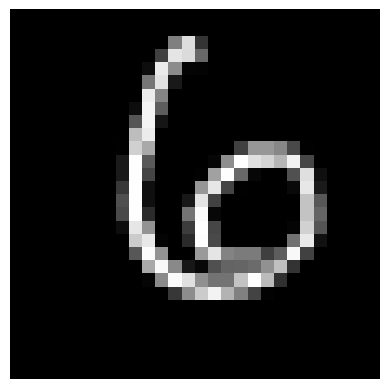

y-Test:  6
prediction:  6
Certainty:  0.9521860749660175


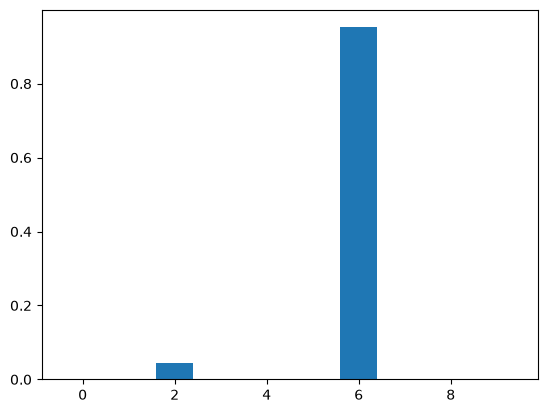

In [4]:
# Show test image 100 with its label and the model's prediction
X_test = mnist.load_images(mnist.key_file["test_img"])
y_test = mnist.load_labels(mnist.key_file["test_label"])

n = 100
y = mnist.predict(X_test[n]/255.)
plt.imshow(X_test[n].reshape((28, -1)), cmap='gray')
plt.axis('off')
plt.show()
print("y-Test: ", y_test[n])
print("prediction: ", np.argmax(y))
print("Certainty: ", np.max(y))
plt.bar(np.arange(0, 10), y)
plt.show()

In [5]:
# Accuracy over the whole test set
correct = 0
for i in range(len(X_test)):
    if np.argmax(mnist.predict(X_test[i]/255.)) == y_test[i]:
        correct += 1
print("accuracy:", correct / len(X_test))

accuracy: 0.9352


## my handwritten digits

i wrote 0-9 five times on one sheet (`digits_sheet.jpg`) and cut each digit out into its own 28x28 grayscale picture, white digit on black like mnist. they are saved as `n_m.png` in `my_digits/` (row m of the sheet is version m).

each one is shown with imshow and then checked against the digit in its file name.

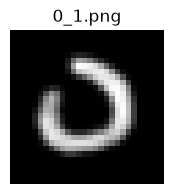

Success: Image 0_1.png is for digit 0 is recognized as 0.


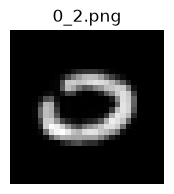

Fail: Image 0_2.png is for digit 0 but the inference result is 7.


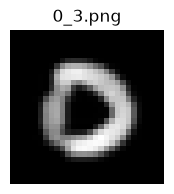

Success: Image 0_3.png is for digit 0 is recognized as 0.


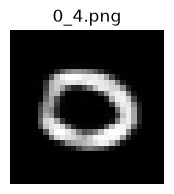

Success: Image 0_4.png is for digit 0 is recognized as 0.


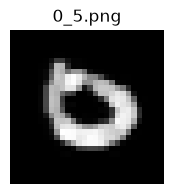

Fail: Image 0_5.png is for digit 0 but the inference result is 6.


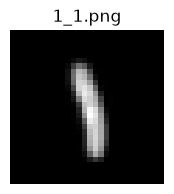

Success: Image 1_1.png is for digit 1 is recognized as 1.


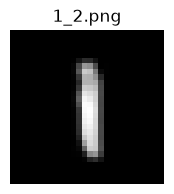

Success: Image 1_2.png is for digit 1 is recognized as 1.


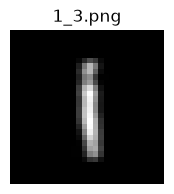

Success: Image 1_3.png is for digit 1 is recognized as 1.


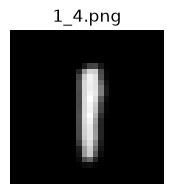

Success: Image 1_4.png is for digit 1 is recognized as 1.


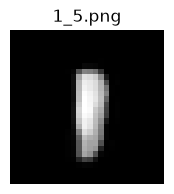

Success: Image 1_5.png is for digit 1 is recognized as 1.


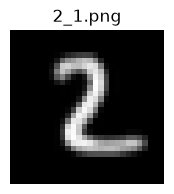

Success: Image 2_1.png is for digit 2 is recognized as 2.


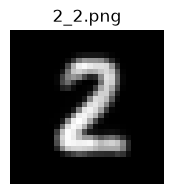

Success: Image 2_2.png is for digit 2 is recognized as 2.


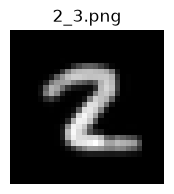

Success: Image 2_3.png is for digit 2 is recognized as 2.


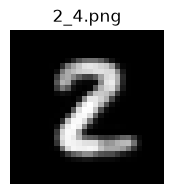

Success: Image 2_4.png is for digit 2 is recognized as 2.


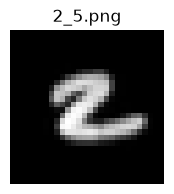

Fail: Image 2_5.png is for digit 2 but the inference result is 6.


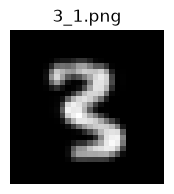

Success: Image 3_1.png is for digit 3 is recognized as 3.


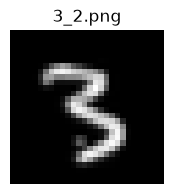

Success: Image 3_2.png is for digit 3 is recognized as 3.


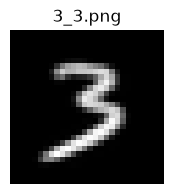

Success: Image 3_3.png is for digit 3 is recognized as 3.


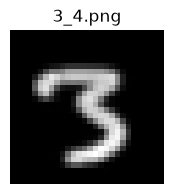

Success: Image 3_4.png is for digit 3 is recognized as 3.


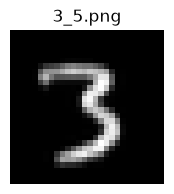

Success: Image 3_5.png is for digit 3 is recognized as 3.


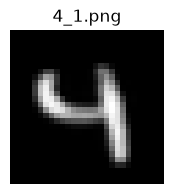

Success: Image 4_1.png is for digit 4 is recognized as 4.


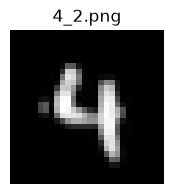

Success: Image 4_2.png is for digit 4 is recognized as 4.


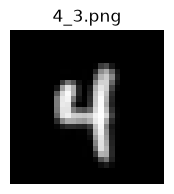

Success: Image 4_3.png is for digit 4 is recognized as 4.


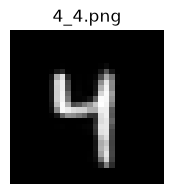

Success: Image 4_4.png is for digit 4 is recognized as 4.


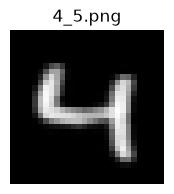

Success: Image 4_5.png is for digit 4 is recognized as 4.


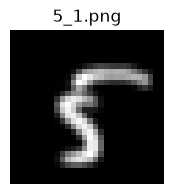

Success: Image 5_1.png is for digit 5 is recognized as 5.


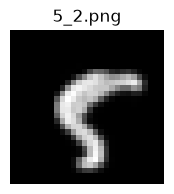

Success: Image 5_2.png is for digit 5 is recognized as 5.


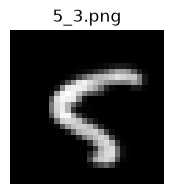

Success: Image 5_3.png is for digit 5 is recognized as 5.


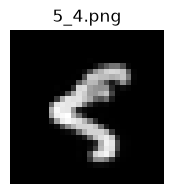

Fail: Image 5_4.png is for digit 5 but the inference result is 4.


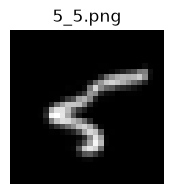

Fail: Image 5_5.png is for digit 5 but the inference result is 4.


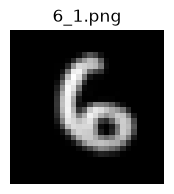

Success: Image 6_1.png is for digit 6 is recognized as 6.


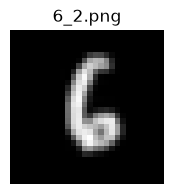

Success: Image 6_2.png is for digit 6 is recognized as 6.


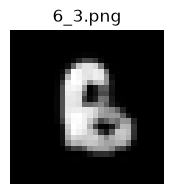

Success: Image 6_3.png is for digit 6 is recognized as 6.


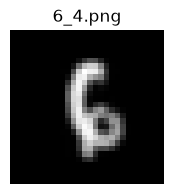

Success: Image 6_4.png is for digit 6 is recognized as 6.


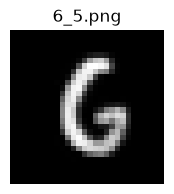

Success: Image 6_5.png is for digit 6 is recognized as 6.


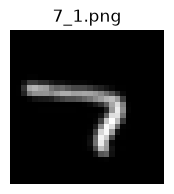

Success: Image 7_1.png is for digit 7 is recognized as 7.


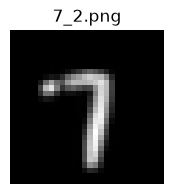

Success: Image 7_2.png is for digit 7 is recognized as 7.


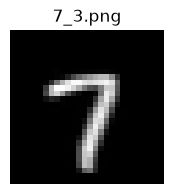

Success: Image 7_3.png is for digit 7 is recognized as 7.


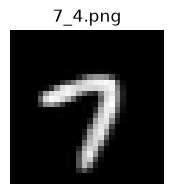

Success: Image 7_4.png is for digit 7 is recognized as 7.


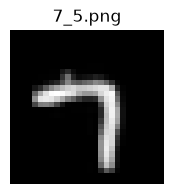

Success: Image 7_5.png is for digit 7 is recognized as 7.


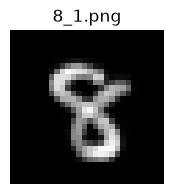

Success: Image 8_1.png is for digit 8 is recognized as 8.


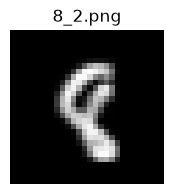

Fail: Image 8_2.png is for digit 8 but the inference result is 1.


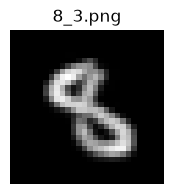

Fail: Image 8_3.png is for digit 8 but the inference result is 5.


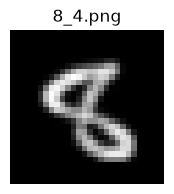

Fail: Image 8_4.png is for digit 8 but the inference result is 5.


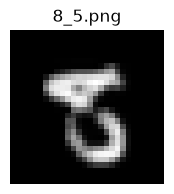

Fail: Image 8_5.png is for digit 8 but the inference result is 5.


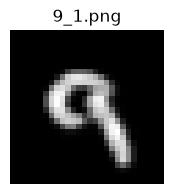

Success: Image 9_1.png is for digit 9 is recognized as 9.


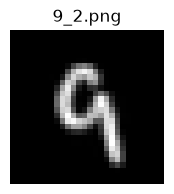

Fail: Image 9_2.png is for digit 9 but the inference result is 4.


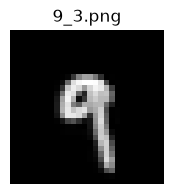

Fail: Image 9_3.png is for digit 9 but the inference result is 4.


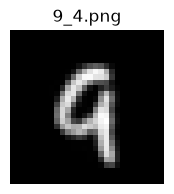

Success: Image 9_4.png is for digit 9 is recognized as 9.


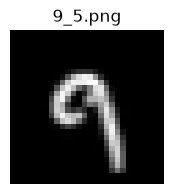

Success: Image 9_5.png is for digit 9 is recognized as 9.
39 / 50 correct


In [6]:
# Run every n_m.png in my_digits/ and print Success or Fail for each one
image_dir = "my_digits"
total, right = 0, 0
for n in range(10):
    for m in range(1, 6):
        file_name = f"{n}_{m}.png"
        path = os.path.join(image_dir, file_name)
        if not os.path.exists(path):
            print(f"missing {path}")
            continue

        x = mnist.load_my_image(path)
        y = mnist.predict(x)
        result = np.argmax(y)

        plt.figure(figsize=(2, 2))
        plt.imshow(x.reshape((28, -1)), cmap='gray')
        plt.title(file_name)
        plt.axis('off')
        plt.show()

        total += 1
        if result == n:
            right += 1
            print(f"Success: Image {file_name} is for digit {n} is recognized as {result}.")
        else:
            print(f"Fail: Image {file_name} is for digit {n} but the inference result is {result}.")

if total > 0:
    print(f"{right} / {total} correct")